# Oil Well Development Site Selection: Predictive Modeling & Bootstrapping Risk Analysis

## Introduction

Selecting the optimal geographic region for new oil well development requires balancing expected crude reserve volume against capital expenditure and geological uncertainty. In this project, we evaluate geological survey data across three candidate regions (`Region 0`, `Region 1`, and `Region 2`) for **OilyGiant**, with the objective of identifying the highest-return, lowest-risk location for deploying 200 new production wells.

### Business Parameters & Decision Criteria
* **Exploration Sample Size:** 500 candidate points surveyed per region; the top **200 wells** with the highest predicted reserve volumes are selected for development.
* **Development Budget:** **100,000,000 USD** (100M) allocated for developing 200 wells in the chosen region (500,000 USD per well).
* **Unit Revenue:** **4,500 USD** per thousand barrels of reserves (`product` is measured in thousands of barrels, so 1 unit = 4,500 USD).
* **Break-Even Threshold:** Each well must generate at least \(\frac{100,000,000\ \text{USD}}{200 \times 4,500\ \text{USD per thousand barrels}} \approx 111.11\) thousand barrels on average to avoid financial loss.
* **Risk Tolerance:** Only regions with a **probability of loss strictly below 2.5%** qualify for investment; among qualifying regions, the one with the **highest average expected profit** is selected.

### Analytical Workflow
1. **Data Loading & Exploratory Data Analysis (EDA):** Inspect schema, missing values, duplicate well identifiers, feature distributions, and linear correlations across all three regional datasets.
2. **Predictive Modeling (Linear Regression):** Train and validate region-specific linear regression models (75:25 train-validation split) to predict well reserve volumes and evaluate model accuracy via RMSE.
3. **Profit Calculation & Break-Even Benchmarking:** Implement deterministic revenue and net profit calculation functions for the top 200 predicted wells per region.
4. **Bootstrapping Risk & Return Simulation:** Execute 1,000 bootstrap iterations (sampling 500 candidate sites per iteration) to estimate the profit distribution, mean expected profit, 95% confidence interval, and empirical risk of loss for each region.

## 1. Environment Setup & Data Loading

We begin by importing the required scientific computing, visualization, and machine learning libraries, establishing consistent visual styling, and loading the three regional datasets (`geo_data_0.csv`, `geo_data_1.csv`, and `geo_data_2.csv`). Note that the CSV files are loaded from the local working directory (with a fallback check for `./datasets/` so the notebook runs seamlessly across environments).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Set consistent visualization styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Load datasets with automatic path resolution
def load_region_data(filename):
    candidate_paths = [
        filename,
        os.path.join('datasets', filename),
        os.path.join('/datasets', filename)
    ]
    for candidate in candidate_paths:
        if os.path.exists(candidate):
            return pd.read_csv(candidate)
    raise FileNotFoundError(
        f"Could not locate {filename}. Place the CSV in the notebook directory "
        "or in a 'datasets' folder."
    )

geo_0 = load_region_data('geo_data_0.csv')
geo_1 = load_region_data('geo_data_1.csv')
geo_2 = load_region_data('geo_data_2.csv')

regions = {'Region 0': geo_0, 'Region 1': geo_1, 'Region 2': geo_2}

for name, df in regions.items():
    print(f"=== {name} | Shape: {df.shape} ===")
    print(df.head(3).to_string(index=False))
    print()

=== Region 0 | Shape: (100000, 5) ===
   id       f0        f1       f2    product
txEyH 0.705745 -0.497823 1.221170 105.280062
2acmU 1.334711 -0.340164 4.365080  73.037750
409Wp 1.022732  0.151990 1.419926  85.265647

=== Region 1 | Shape: (100000, 5) ===
   id         f0        f1        f2    product
kBEdx -15.001348 -8.276000 -0.005876   3.179103
62mP7  14.272088 -3.475083  0.999183  26.953261
vyE1P   6.263187 -5.948386  5.001160 134.766305

=== Region 2 | Shape: (100000, 5) ===
   id        f0       f1        f2   product
fwXo0 -1.146987 0.963328 -0.828965 27.758673
WJtFt  0.262778 0.269839 -2.530187 56.069697
ovLUW  0.194587 0.289035 -5.586433 62.871910



### Initial Inspection Takeaways
Each regional dataset contains **100,000 records** and **5 columns**:
* `id`: Unique alphanumeric well identifier.
* `f0`, `f1`, `f2`: Standardized/proprietary geological features representing subsurface characteristics.
* `product`: Volume of crude oil reserves in the well (expressed in **thousands of barrels**).

Next, we audit data integrity—checking data types, missing values, exact row duplicates, and duplicate `id` entries—and compute summary statistics across all three regions.

In [2]:
# Data quality audit: schema, completeness, duplicates, and summary statistics
for name, df in regions.items():
    print(f"--- Data Quality Audit: {name} ---")
    print("\nDataFrame information:")
    df.info()

    print("\nMissing values:")
    print(df.isnull().sum().to_string())
    print(f"Exact duplicate rows: {df.duplicated().sum()}")
    print(f"Duplicate well IDs: {df['id'].duplicated().sum()}")

    duplicate_id_rows = df[df['id'].duplicated(keep=False)].sort_values('id')
    if not duplicate_id_rows.empty:
        print("\nRows sharing duplicated well IDs (first 10 rows):")
        print(duplicate_id_rows.head(10).to_string(index=False))

    print("\nNumeric summary statistics:")
    print(df.describe().round(4))
    print("\n" + "=" * 65 + "\n")

--- Data Quality Audit: Region 0 ---

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  str    
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), str(1)
memory usage: 3.8 MB

Missing values:
id         0
f0         0
f1         0
f2         0
product    0
Exact duplicate rows: 0
Duplicate well IDs: 10

Rows sharing duplicated well IDs (first 10 rows):
   id        f0        f1        f2    product
74z30  1.084962 -0.312358  6.990771 127.643327
74z30  0.741456  0.459229  5.153109 140.771492
A5aEY -0.180335  0.935548 -2.094773  33.020205
A5aEY -0.039949  0.156872  0.209861  89.249364
AGS9W -0.933795  0.116194 -3.655896  19.230453
AGS9W  1.454747 -0.479651  0.683380 126.370504
HZww2  0.75

### Data Quality & Statistical Summary Analysis

* **Completeness & Types:** All three datasets contain 100,000 records and have no missing values or exact duplicate rows. All columns are `float64` except `id`, which is stored as `object` (text), as shown by `df.info()` above.
* **Duplicate Well Identifiers:** The audit identifies 10 repeated `id` entries in Region 0 and 4 in each of Regions 1 and 2. The rows printed above show that each repeated `id` carries different feature and `product` values, so they are distinct measurements rather than duplicate records. They are retained for that reason. Because `id` is excluded from the predictive features, repeated identifiers do not affect the model.
* **Reserve Volume (`product`) Baselines:**
  * **Region 0:** Mean = `92.50` thousand barrels (standard deviation = `44.29`), median = `91.85`.
  * **Region 1:** Mean = `68.83` thousand barrels (standard deviation = `45.94`), median = `57.09`. Its `f2` values range from approximately `-0.02` to `5.02`.
  * **Region 2:** Mean = `95.00` thousand barrels (standard deviation = `44.75`), median = `94.93`, the highest unconditional average among the regions.
* **Break-Even Context:** The required average for the 200 developed wells is `111.11` thousand barrels per well. The unconditional regional averages (92.50, 68.83, and 95.00 thousand barrels) are all below this benchmark. This does not determine the outcome: the business strategy ranks candidate wells by predicted reserves and selects the top 200 from each 500-well exploration sample.

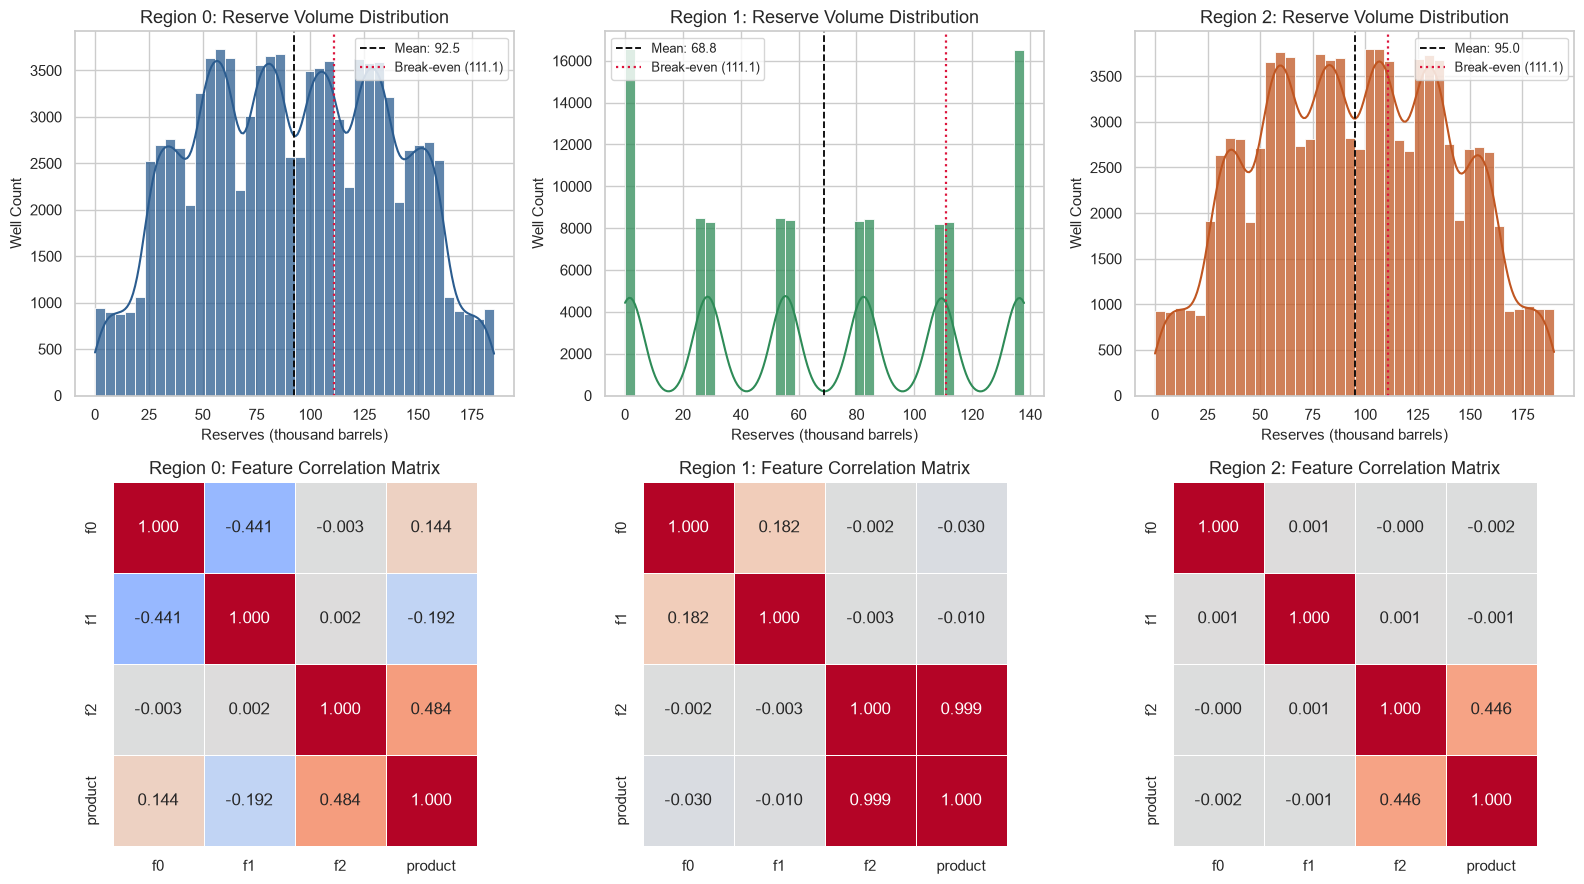

In [3]:
# Visualize target variable ('product') distributions and feature correlations across regions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

colors = ['#2b5c8f', '#2e8b57', '#c05621']

for idx, (name, df) in enumerate(regions.items()):
    # Top row: Reserve volume distributions
    ax_hist = axes[0, idx]
    sns.histplot(df['product'], bins=40, kde=True, color=colors[idx], ax=ax_hist, edgecolor='white', alpha=0.75)
    ax_hist.axvline(df['product'].mean(), color='black', linestyle='--', linewidth=1.3, label=f"Mean: {df['product'].mean():.1f}")
    ax_hist.axvline(111.11, color='crimson', linestyle=':', linewidth=1.6, label='Break-even (111.1)')
    ax_hist.set_title(f"{name}: Reserve Volume Distribution")
    ax_hist.set_xlabel("Reserves (thousand barrels)")
    ax_hist.set_ylabel("Well Count")
    ax_hist.legend(fontsize=9)

    # Bottom row: Correlation heatmaps
    ax_corr = axes[1, idx]
    corr_matrix = df[['f0', 'f1', 'f2', 'product']].corr()
    sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1,
                cbar=False, ax=ax_corr, square=True, linewidths=0.5)
    ax_corr.set_title(f"{name}: Feature Correlation Matrix")

plt.tight_layout()
plt.show()

### Exploratory Visualization & Correlation Insights

1. **Reserve Distributions (`product`):**
   * **Region 0:** The distribution spans approximately 0 to 185 thousand barrels and has several broad local peaks, without one sharply dominant peak.
   * **Region 1:** The distribution forms distinct reserve levels, with visible concentrations near 0, 30, 55, 80, 110, and 135 thousand barrels. The lowest and highest levels are especially frequent.
   * **Region 2:** The distribution spans approximately 0 to 190 thousand barrels and shows several broad local peaks across the range.

2. **Linear Feature Correlations:**
   * **Region 0:** `f2` has a moderate positive correlation with `product` (`r = 0.484`). The correlations for `f0` (`r = 0.144`) and `f1` (`r = -0.192`) are weaker. `f0` and `f1` have a correlation of approximately `-0.441`.
   * **Region 1:** `f2` has a near-perfect positive correlation with `product` (`r = 0.999`), indicating that a linear model can capture the target relationship very accurately.
   * **Region 2:** `f2` has the strongest relationship with `product` (`r = 0.446`), while `f0` and `f1` have correlations close to zero.

**EDA takeaway:** Region 1 has a clearly structured, tiered target distribution and an exceptionally strong linear relationship between `f2` and `product`. Regions 0 and 2 have broader reserve distributions and more moderate feature-target correlations. These differences support training and evaluating a separate model for each region.

## 2. Predictive Modeling & Validation (Linear Regression)

Per operational modeling standards, we build a dedicated **Linear Regression** model for each region using a **75:25 training-to-validation split** (`random_state=12345` for reproducibility).

For each region, we:
1. Drop the non-predictive `id` column and separate features (`f0`, `f1`, `f2`) from the target (`product`).
2. Fit `LinearRegression` on the 75,000 training observations.
3. Generate predictions on the 25,000 validation observations.
4. Compute the **mean predicted reserve volume** and **Root Mean Squared Error (RMSE)** to evaluate predictive accuracy.

In [4]:
# Reusable model-training and evaluation workflow
RANDOM_STATE = 12345

def train_and_evaluate_region(df, random_state=RANDOM_STATE):
    """Split one region, train Linear Regression, and return predictions and metrics."""
    features = df[['f0', 'f1', 'f2']]
    target = df['product']

    X_train, X_valid, y_train, y_valid = train_test_split(
        features, target, test_size=0.25, random_state=random_state
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = pd.Series(
        model.predict(X_valid),
        index=y_valid.index,
        name='predicted_product'
    )

    rmse = np.sqrt(mean_squared_error(y_valid, predictions))

    return {
        'model': model,
        'y_valid': y_valid,
        'predictions': predictions,
        'mean_pred': predictions.mean(),
        'mean_actual': y_valid.mean(),
        'rmse': rmse
    }


def evaluate_all_regions(region_data):
    """Apply the same training and evaluation workflow to every region."""
    return {
        name: train_and_evaluate_region(df)
        for name, df in region_data.items()
    }


model_results = evaluate_all_regions(regions)

summary_df = pd.DataFrame([
    {
        'Region': name,
        'Validation Samples': len(result['y_valid']),
        'Actual Mean Reserves (k bbl)': round(result['mean_actual'], 2),
        'Predicted Mean Reserves (k bbl)': round(result['mean_pred'], 2),
        'Validation RMSE (k bbl)': round(result['rmse'], 2),
        'RMSE / Target Std Ratio': round(
            result['rmse'] / result['y_valid'].std(), 4
        )
    }
    for name, result in model_results.items()
])

print(summary_df.to_string(index=False))

  Region  Validation Samples  Actual Mean Reserves (k bbl)  Predicted Mean Reserves (k bbl)  Validation RMSE (k bbl)  RMSE / Target Std Ratio
Region 0               25000                         92.08                            92.59                    37.58                   0.8485
Region 1               25000                         68.72                            68.73                     0.89                   0.0194
Region 2               25000                         94.88                            94.97                    40.03                   0.8915


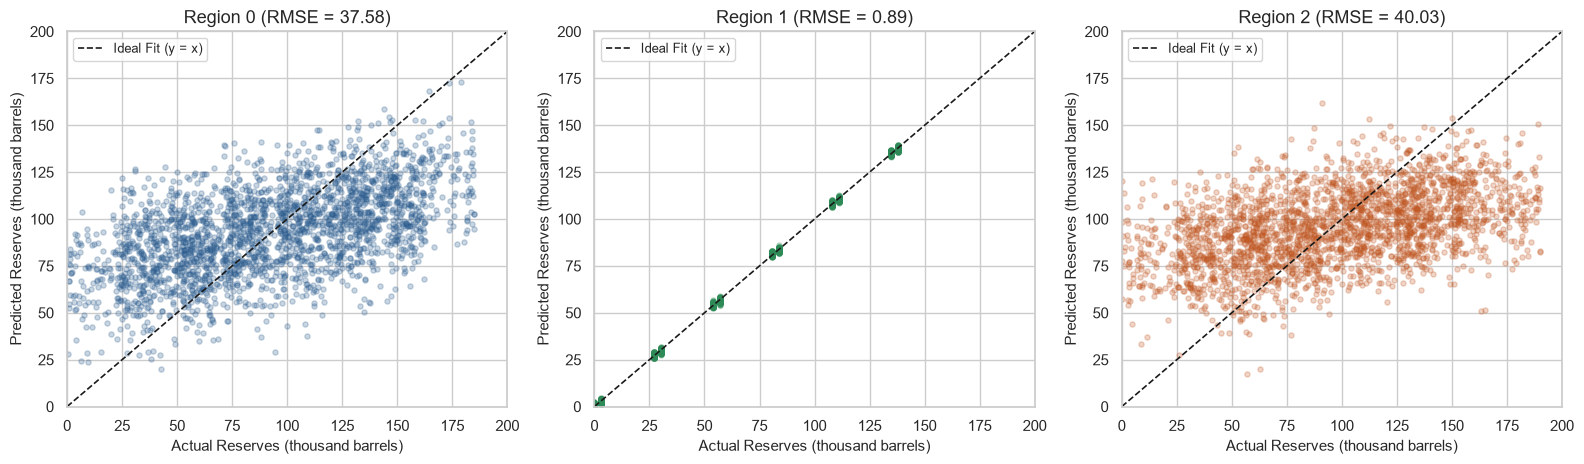

In [5]:
# Visualize Actual vs. Predicted Reserves across the three validation sets
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for idx, (name, res) in enumerate(model_results.items()):
    ax = axes[idx]
    # Sample 2,500 validation points for clean scatter rendering
    sample_idx = res['y_valid'].sample(2500, random_state=RANDOM_STATE).index
    ax.scatter(
        res['y_valid'].loc[sample_idx],
        res['predictions'].loc[sample_idx],
        alpha=0.25, s=14, color=colors[idx]
    )
    lims = [0, 200]
    ax.plot(lims, lims, 'k--', linewidth=1.2, label='Ideal Fit (y = x)')
    ax.set_title(f"{name} (RMSE = {res['rmse']:.2f})")
    ax.set_xlabel("Actual Reserves (thousand barrels)")
    ax.set_ylabel("Predicted Reserves (thousand barrels)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

### Model Performance Analysis

* **Region 1 — Highest Predictive Precision:** The correlation between `f2` and reserve volume is nearly perfect (`r = 0.999`). Linear Regression therefore achieves a very low **RMSE of 0.89 thousand barrels** (approximately 890 barrels), and the actual-versus-predicted points lie close to the identity line. Its predicted mean reserve volume is the lowest of the three regions (`68.73` thousand barrels).
* **Regions 0 and 2 — Higher Average Reserves, Larger Prediction Errors:**
  * **Region 0** has a predicted mean of **92.59 thousand barrels** and an **RMSE of 37.58 thousand barrels**.
  * **Region 2** has the highest predicted mean (**94.97 thousand barrels**) and an **RMSE of 40.03 thousand barrels**.
* **Strategic Implication:** Regions 0 and 2 have higher average reserve volumes but substantial prediction errors, approximately 38–40 thousand barrels. Their top-ranked predictions may therefore overestimate actual reserves. Region 1 has a lower overall mean, but its reserve estimates are much more precise. The deterministic profit benchmark and bootstrap simulation will determine whether that precision translates into a better risk-adjusted investment.

## 3. Deterministic Profit Calculation & Break-Even Analysis

We define the business parameters and two complementary functions:

1. `select_top_wells` ranks candidate wells by predicted reserve volume and returns the 200 highest-ranked observations together with their actual reserve volumes.
2. `calculate_profit` receives an already selected group of wells, sums its actual reserves, calculates gross revenue, and subtracts the development budget.

The net profit formula is:

\[
\text{Net Profit (USD)} =
(\text{Total Actual Reserves in thousand barrels} \times 4{,}500\ \text{USD})
- 100{,}000{,}000\ \text{USD}
\]

We first use all 25,000 validation observations as a deterministic benchmark candidate pool. This is a comparison benchmark, not the operational 500-candidate exploration process; the bootstrap section models that operational constraint.

In [6]:
# Business constants
EXPLORATION_POINTS = 500       # Candidate wells surveyed per exploration campaign
TOP_WELLS = 200                # Wells selected for development
BUDGET = 100_000_000           # 100 million USD development budget
REVENUE_PER_UNIT = 4_500       # USD per thousand barrels of reserves

# Break-even reserve calculations
break_even_total_volume = BUDGET / REVENUE_PER_UNIT
break_even_per_well = break_even_total_volume / TOP_WELLS

print(
    f"Minimum total reserves required across 200 wells: "
    f"{break_even_total_volume:,.2f} thousand barrels"
)
print(
    f"Minimum average reserves required per well: "
    f"{break_even_per_well:.2f} thousand barrels\n"
)


def select_top_wells(target, predictions, count=TOP_WELLS):
    """Return the top predicted wells together with their actual reserves."""
    selection = pd.DataFrame({
        'actual_reserves': target.to_numpy(),
        'predicted_reserves': predictions.to_numpy()
    })
    return selection.sort_values(
        'predicted_reserves', ascending=False
    ).head(count).reset_index(drop=True)


def calculate_profit(selected_wells):
    """Calculate net profit in USD from a previously selected set of wells."""
    total_actual_reserves = selected_wells['actual_reserves'].sum()
    gross_revenue = total_actual_reserves * REVENUE_PER_UNIT
    return gross_revenue - BUDGET


# Select and store the top 200 wells once per region for all later analysis.
top_wells_by_region = {}
deterministic_results = []

for name, result in model_results.items():
    selected_wells = select_top_wells(
        result['y_valid'], result['predictions'], TOP_WELLS
    )
    top_wells_by_region[name] = selected_wells

    average_reserves = selected_wells['actual_reserves'].mean()
    net_profit = calculate_profit(selected_wells)

    deterministic_results.append({
        'Region': name,
        'Selected Wells': len(selected_wells),
        'Average Actual Reserves (k bbl)': average_reserves,
        'Net Profit (USD)': net_profit
    })

deterministic_df = pd.DataFrame(deterministic_results)
print("--- Full Validation Set Top-200 Benchmark ---")
print(deterministic_df.to_string(index=False, formatters={
    'Average Actual Reserves (k bbl)': '{:.2f}'.format,
    'Net Profit (USD)': '{:,.2f}'.format
}))

Minimum total reserves required across 200 wells: 22,222.22 thousand barrels
Minimum average reserves required per well: 111.11 thousand barrels

--- Full Validation Set Top-200 Benchmark ---
  Region  Selected Wells Average Actual Reserves (k bbl) Net Profit (USD)
Region 0             200                          148.01    33,208,260.43
Region 1             200                          137.95    24,150,866.97
Region 2             200                          141.23    27,103,499.64


### Deterministic Benchmark Analysis

* **Break-Even Benchmark:** A development budget of 100 million USD and revenue of 4,500 USD per thousand barrels require at least **22,222.22 thousand barrels** across the 200 developed wells, or **111.11 thousand barrels per well** on average.
* **Unconditional Averages vs. Break-Even:** The full-dataset average reserves are **92.50 thousand barrels in Region 0**, **68.83 thousand barrels in Region 1**, and **95.00 thousand barrels in Region 2**. Each is below the 111.11-thousand-barrel per-well benchmark. These are averages across all surveyed wells, not the averages of the selected top 200; predictive ranking is intended to identify a higher-reserve subset.
* **Full-Validation Top-200 Performance:** Selecting the 200 highest predicted wells from all 25,000 validation observations yields estimated net profits of **33.21 million USD in Region 0**, **24.15 million USD in Region 1**, and **27.10 million USD in Region 2**. All three deterministic selections exceed break-even.
* **Preliminary Recommendation — Region 0:** On this full-validation benchmark alone, Region 0 ranks first with 33.21 million USD in estimated net profit. This is preliminary because the operational process evaluates only 500 candidate points per campaign before selecting 200 wells. The bootstrap simulation below evaluates the variability and downside risk introduced by that smaller candidate pool.

## 4. Bootstrapping Risk & Return Simulation (1,000 Iterations)

To estimate exploration outcomes under the operational sampling process, we apply non-parametric bootstrapping with **1,000 iterations** and a fixed random seed (`12345`):

1. Draw 500 wells with replacement from each region's 25,000-observation validation set.
2. Rank the sampled wells by predicted reserves and select the top 200.
3. Calculate the realized net profit for those 200 wells using `calculate_profit`.
4. Summarize the 1,000 simulated campaigns using:
   * **Mean Expected Profit** (USD)
   * **95% Confidence Interval** (2.5th and 97.5th percentiles)
   * **Probability of Loss** (percentage of campaigns with net profit below zero)

A region qualifies only when its empirical probability of loss is **strictly below 2.5%**. Among qualifying regions, the region with the highest mean expected profit is preferred.

In [7]:
# Run 1,000 bootstrap exploration campaigns for each region
BOOTSTRAP_ITERATIONS = 1000
state = np.random.RandomState(RANDOM_STATE)

bootstrap_profits = {}
risk_metrics = []

for name, result in model_results.items():
    target = result['y_valid'].reset_index(drop=True)
    predictions = result['predictions'].reset_index(drop=True)
    profits = []

    for _ in range(BOOTSTRAP_ITERATIONS):
        sample_indices = state.choice(
            len(target), size=EXPLORATION_POINTS, replace=True
        )
        sampled_target = target.iloc[sample_indices].reset_index(drop=True)
        sampled_predictions = predictions.iloc[sample_indices].reset_index(drop=True)

        # Reuse the same selection logic used in the deterministic benchmark.
        selected_sample = select_top_wells(
            sampled_target, sampled_predictions, TOP_WELLS
        )
        profits.append(calculate_profit(selected_sample))

    profits = pd.Series(profits, name='net_profit_usd')
    bootstrap_profits[name] = profits

    mean_profit = profits.mean()
    ci_lower = profits.quantile(0.025)
    ci_upper = profits.quantile(0.975)
    loss_risk_pct = (profits < 0).mean() * 100

    risk_metrics.append({
        'Region': name,
        'Mean Profit (USD Millions)': round(mean_profit / 1e6, 3),
        '95% CI Lower (USD Millions)': round(ci_lower / 1e6, 3),
        '95% CI Upper (USD Millions)': round(ci_upper / 1e6, 3),
        'Risk of Loss (%)': round(loss_risk_pct, 2),
        'Meets <2.5% Risk Criteria': 'PASS' if loss_risk_pct < 2.5 else 'FAIL'
    })

risk_df = pd.DataFrame(risk_metrics)
print(risk_df.to_string(index=False))

  Region  Mean Profit (USD Millions)  95% CI Lower (USD Millions)  95% CI Upper (USD Millions)  Risk of Loss (%) Meets <2.5% Risk Criteria
Region 0                       3.962                       -1.112                        9.098               6.9                      FAIL
Region 1                       4.612                        0.781                        8.630               0.7                      PASS
Region 2                       3.930                       -1.122                        9.346               6.5                      FAIL


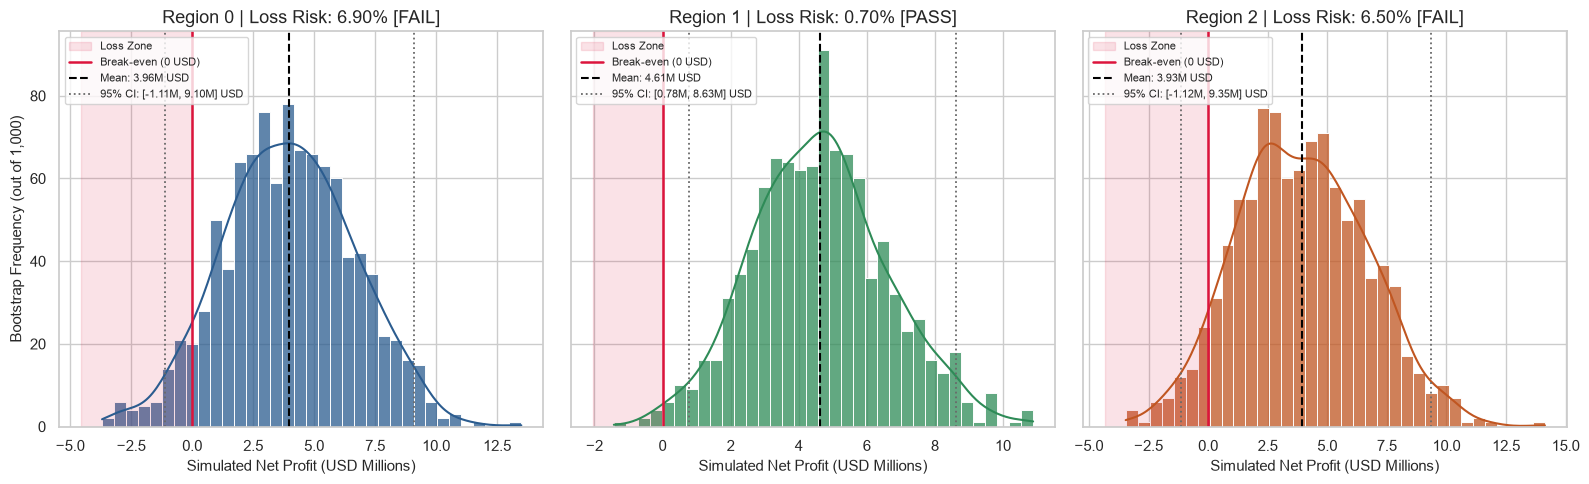

In [8]:
# Visualize bootstrap profit distributions, confidence intervals, and loss zones
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for idx, (name, profits) in enumerate(bootstrap_profits.items()):
    ax = axes[idx]
    profits_m = profits / 1e6
    mean_val = profits_m.mean()
    ci_low = profits_m.quantile(0.025)
    ci_high = profits_m.quantile(0.975)
    risk_pct = (profits < 0).mean() * 100

    sns.histplot(
        profits_m, bins=35, kde=True, color=colors[idx],
        ax=ax, edgecolor='white', alpha=0.75
    )

    # Shade outcomes below break-even to highlight loss-making campaigns.
    x_min, _ = ax.get_xlim()
    ax.axvspan(x_min, 0, color='crimson', alpha=0.12, label='Loss Zone')
    ax.axvline(0, color='crimson', linestyle='-', linewidth=1.8,
               label='Break-even (0 USD)')
    ax.axvline(mean_val, color='black', linestyle='--', linewidth=1.5,
               label=f'Mean: {mean_val:.2f}M USD')
    ax.axvline(ci_low, color='dimgray', linestyle=':', linewidth=1.3,
               label=f'95% CI: [{ci_low:.2f}M, {ci_high:.2f}M] USD')
    ax.axvline(ci_high, color='dimgray', linestyle=':', linewidth=1.3)

    status = 'PASS' if risk_pct < 2.5 else 'FAIL'
    ax.set_title(f'{name} | Loss Risk: {risk_pct:.2f}% [{status}]')
    ax.set_xlabel('Simulated Net Profit (USD Millions)')
    if idx == 0:
        ax.set_ylabel('Bootstrap Frequency (out of 1,000)')
    ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

### Bootstrap Simulation & Risk Analysis

The 1,000 bootstrap campaigns estimate the results of repeatedly surveying 500 candidate wells and selecting the 200 highest-ranked wells. The `risk_df` table above summarizes the results used for the investment decision.

1. **Region 0 — Does Not Qualify**
   * **Mean Expected Net Profit:** **3.962 million USD**.
   * **95% Confidence Interval:** **-1.112 to 9.098 million USD**.
   * **Probability of Loss:** **6.90%**.
   * This exceeds the strict 2.5% risk limit, so Region 0 fails the investment gate. Its confidence interval also extends below zero, consistent with a material downside risk.

2. **Region 1 — Qualifies**
   * **Mean Expected Net Profit:** **4.612 million USD**.
   * **95% Confidence Interval:** **0.781 to 8.630 million USD**.
   * **Probability of Loss:** **0.70%**.
   * This is the only region with an observed loss probability strictly below 2.5%. Its confidence interval is entirely above zero in this simulation, and it passes the investment gate.

3. **Region 2 — Does Not Qualify**
   * **Mean Expected Net Profit:** **3.930 million USD**.
   * **95% Confidence Interval:** **-1.122 to 9.346 million USD**.
   * **Probability of Loss:** **6.50%**.
   * This exceeds the 2.5% limit and fails the investment gate. Its confidence interval extends below zero.

**Bootstrap recommendation — Region 1.** Apply the risk filter first: Regions 0 and 2 are excluded because their loss probabilities are 6.90% and 6.50%, respectively. Region 1 is the sole qualifying region, with a mean expected net profit of 4.612 million USD and a loss probability of 0.70%.

**Comparison with the deterministic benchmark:** The full-validation top-200 benchmark favored Region 0 with 33.21 million USD, while the bootstrap analysis selects Region 1. These results answer different questions. The deterministic benchmark ranks 200 wells from the entire 25,000-observation validation set; each bootstrap campaign first samples only 500 candidate wells and then selects 200. This smaller candidate pool introduces sampling variability. In Regions 0 and 2, the much larger prediction errors (RMSE values of 37.58 and 40.03 thousand barrels) make it harder to rank high-reserve wells reliably, contributing to higher simulated downside risk. Region 1's RMSE of 0.89 thousand barrels supports much more reliable ranking and is consistent with its lower observed loss probability.

## Conclusion & Strategic Recommendation

### Executive Summary of Findings

The table below consolidates the validation, deterministic benchmark, and bootstrap results. Financial values are expressed in USD to avoid currency-symbol formatting ambiguity.

| Evaluation Metric | Region 0 | **Region 1 (Recommended)** | Region 2 |
| :--- | :---: | :---: | :---: |
| **Mean Actual Reserves (thousand barrels)** | 92.50 | 68.83 | 95.00 |
| **Linear Regression RMSE (thousand barrels)** | 37.58 | **0.89** | 40.03 |
| **Deterministic Top-200 Profit (million USD)** | **33.21** | 24.15 | 27.10 |
| **Bootstrap Mean Profit (million USD)** | 3.962 | **4.612** | 3.930 |
| **95% Profit Confidence Interval (million USD)** | [-1.112, 9.098] | **[0.781, 8.630]** | [-1.122, 9.346] |
| **Probability of Loss** | 6.90% | **0.70%** | 6.50% |
| **Investment Gate (risk strictly below 2.5%)** | FAIL | **PASS** | FAIL |

### Final Business Recommendation

**Region 1 is the recommended location for OilyGiant's development investment.**

The deterministic benchmark, which selects the top 200 predicted wells from the entire validation set, initially favors Region 0 with an estimated net profit of 33.21 million USD. However, this benchmark does not reflect the operational exploration process, which surveys only 500 candidate points before selecting 200 wells.

The bootstrap simulation models that operational constraint over 1,000 repeated campaigns. Under the required rule that the probability of loss must be strictly below 2.5%, **Region 0 (6.90%) and Region 2 (6.50%) are disqualified**. **Region 1 is the only qualifying region**, with a mean expected net profit of **4.612 million USD**, a 95% confidence interval of **0.781 to 8.630 million USD**, and a loss probability of **0.70%**.

Region 1 also has the lowest prediction error (**RMSE = 0.89 thousand barrels**) and a near-perfect linear relationship between `f2` and `product` (`r = 0.999`). This predictive precision helps the model rank candidate wells more reliably in each 500-point exploration sample. By contrast, the higher RMSE values in Regions 0 and 2 (37.58 and 40.03 thousand barrels) are accompanied by substantially higher simulated loss probabilities.

**The final recommendation therefore changes from Region 0 in the deterministic full-validation benchmark to Region 1 after bootstrap risk assessment.** This is a deliberate consequence of applying the operational sampling process and the specified risk threshold, not a contradiction between the analyses.

### Limitations and Next Steps

The bootstrap results are empirical estimates based on 1,000 resamples of the available validation data. They quantify sampling variability under the assumptions of this analysis, but they do not guarantee future field performance. Before committing capital, OilyGiant should validate the geological assumptions, operational costs, commodity-price assumptions, and model stability with additional field and financial due diligence.